# Import Libraries

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import *

# Load Dataset

In [3]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


# Variables Description & Statistical Analysis
- **Pregnancies** : How many times the woman has been pregnant
- **Glucose** : Concentration of plasma glucose
- **BloodPressure** : Diastolic blood pressure
- **SkinThickness** : Skinfold thickness
- **Insulin** : Insulin level in blood
- **BMI** : Body Mass Index
- **DiabetesPedigreeFunction** : A measurement for diabetes risk based on family history
- **Age** : Person's age in years
- **Outcome** : Dependant variable that indicates diabetes status

In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# Plot Variables

array([[<Axes: title={'center': 'Pregnancies'}>,
        <Axes: title={'center': 'Glucose'}>,
        <Axes: title={'center': 'BloodPressure'}>],
       [<Axes: title={'center': 'SkinThickness'}>,
        <Axes: title={'center': 'Insulin'}>,
        <Axes: title={'center': 'BMI'}>],
       [<Axes: title={'center': 'DiabetesPedigreeFunction'}>,
        <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Outcome'}>]], dtype=object)

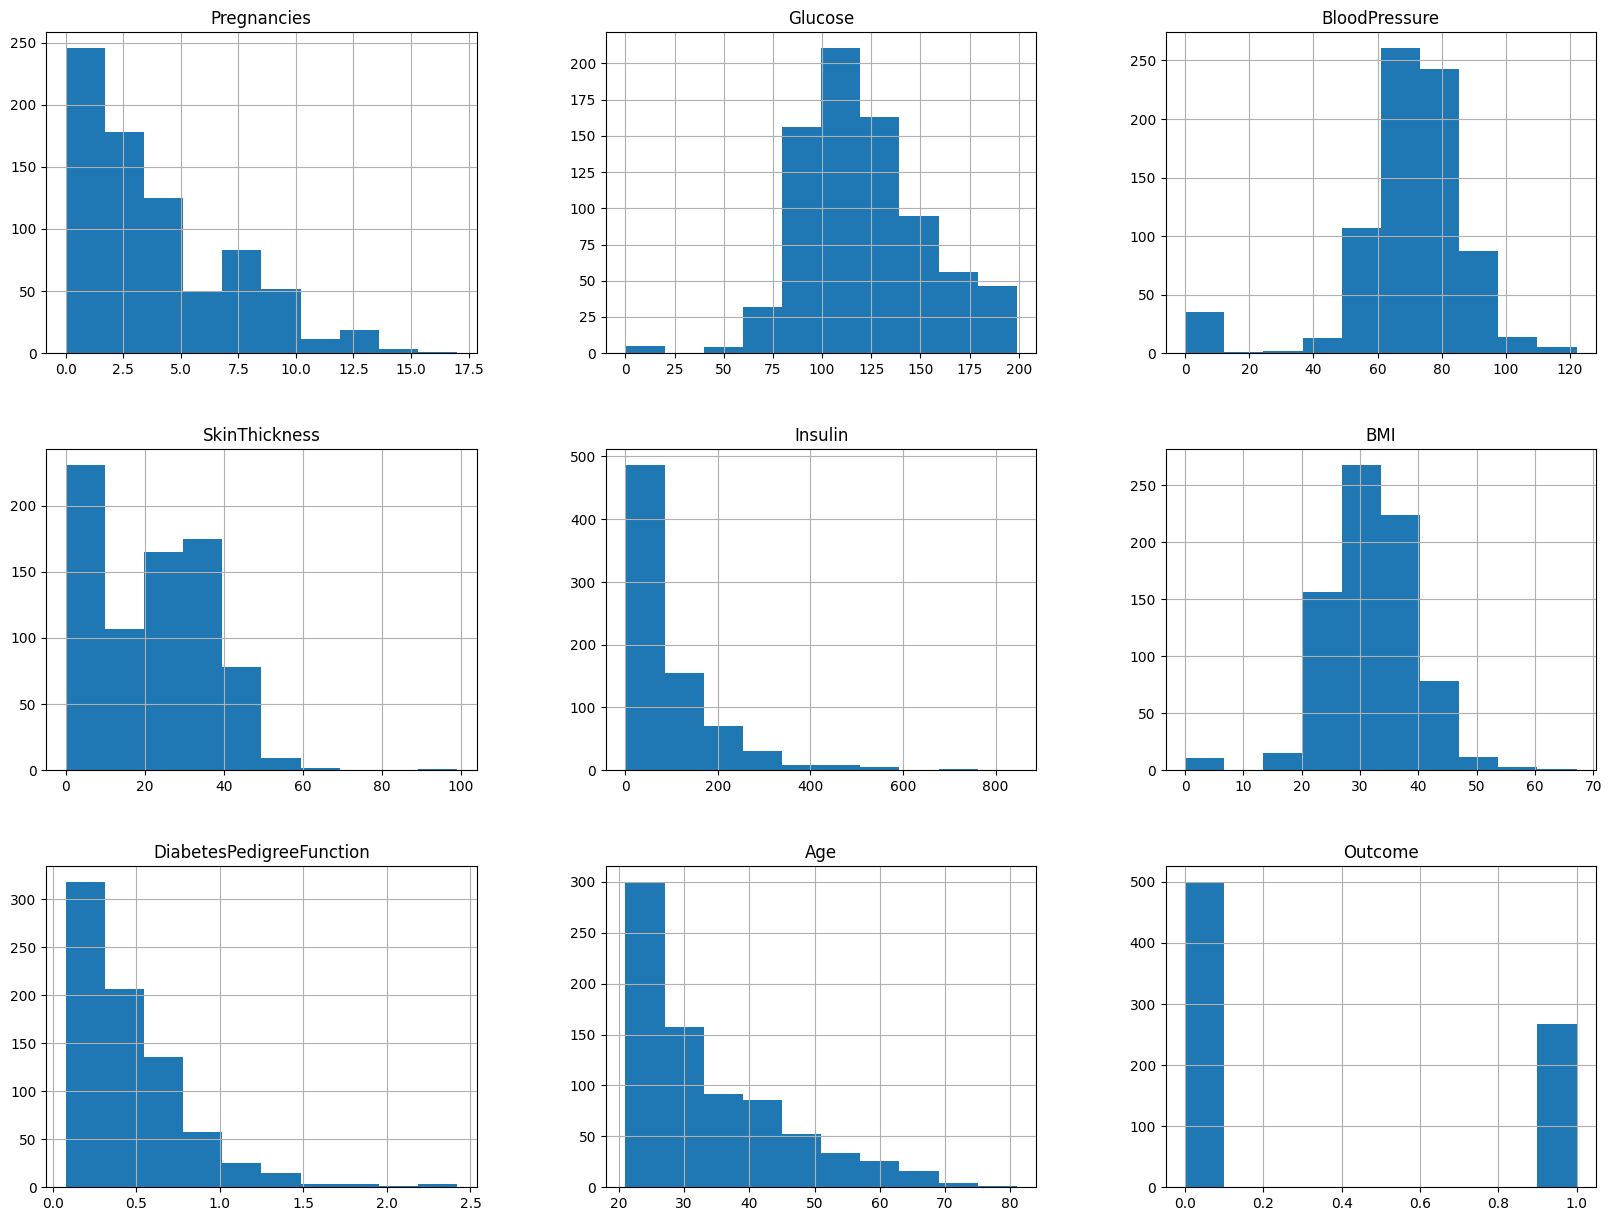

In [5]:
df.hist(figsize=(20,15))

## Maybe the recorded data have miscalculated measurements, because there are many Zero values that may affect to the final calculations




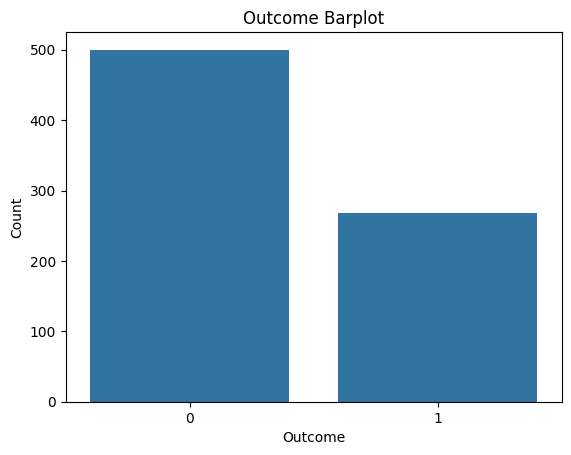

In [6]:
sns.countplot(x='Outcome', data=df)
plt.title('Outcome Barplot')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

# Convert DataFrame to Numpy arrays

In [7]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

# Split Dataset to Train-Test

Train Samples: 537
Test Samples: 231
Seed: 0

Seed enables reproducibility

In [34]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 4), (537,), (231, 4), (231,))

# Create a Logistic Regression Model

In [35]:
model = LogisticRegression(max_iter=5000, random_state=seed)

# Train model on training set

In [36]:
model.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=5000, random_state=0)

# Evaluate Model on test set

In [38]:
y_pred = model.predict(x_test)
y_pred

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0, 160,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  66,   0,
         0,   0, 160,   0,   0,   0,  89,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0, 240,   0, 258,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 142,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,  37,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0, 160,   0,   0,   0,   0,
       310,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   

In [39]:
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 49.35


# Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values $\rightarrow$ more important features

## Data Normalization

In [40]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

## Model Training-Evaluation

In [41]:
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 51.95


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 2 with shape (4,) and arg 3 with shape (8,).

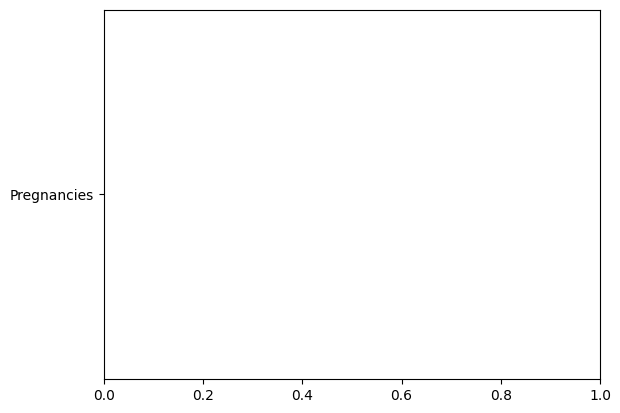

In [42]:
coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

Text(0.5, 1.0, 'Glucose Correllation with Outcome')

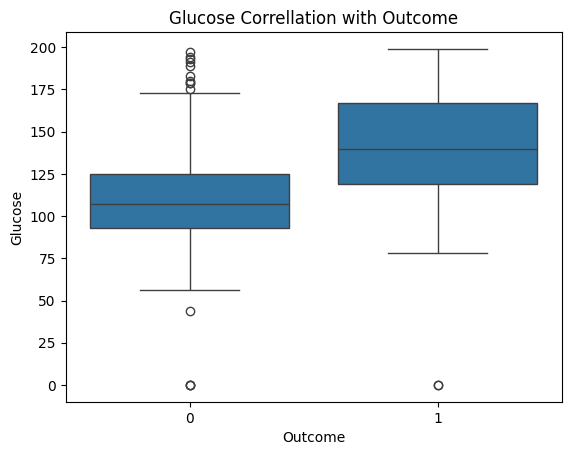

In [43]:
sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.title('Glucose Correllation with Outcome')



## Based on Boxplots it is clearly visible that patients with higher glucose levels are more possible to have diabetes
### - Patients without DIabetes have mean value of Glucose : ~110
### - Patients with Diabetes have mean value of Glucose : ~ 140

# Age Group Creation


In [44]:
age_groups = pd.cut(df['Age'], bins=[0, 25, 50, 100], labels=['0-25', '25-50', '50+'])
df['AgeGroup'] = age_groups

age_group_accuracy = df.groupby('AgeGroup', observed=True)['Outcome'].mean()

Text(0.5, 1.0, 'Age Group Accuracy')

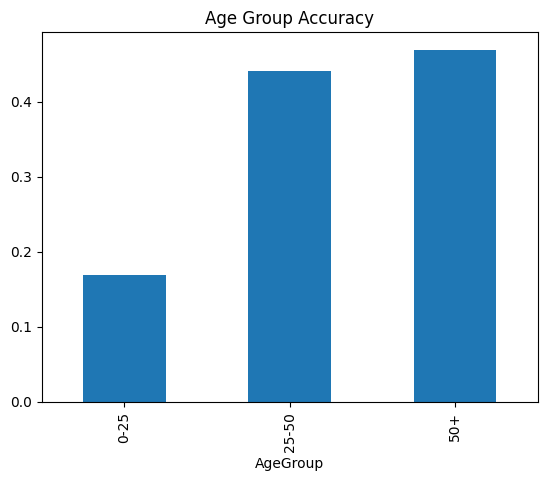

In [45]:
age_group_accuracy.plot(kind='bar')
plt.title('Age Group Accuracy')

# **It's critical for the classifier to eliminate the False Negative results. We dont want to classify patient with diabetes as a healthy person, because this will damage his health and cause bad consequences.**



---





---

# **Part 2**


---



## Dropping attributes and creating train-test split

In [46]:
x = df[['Pregnancies', 'BloodPressure', 'BMI', 'Age']]
y = df['Insulin']

x.to_numpy()
y.to_numpy()

y.shape, x.shape

((768,), (768, 4))

# Training model, Predicting values and Evaluating with MAE

In [47]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

In [53]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred= model.predict(x_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [64]:
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

print(f"Mean Squared Error: {MSE:.3f}")
print(f"Mean Absolute Error: {MAE:.3f}")

Mean Squared Error: 15047.844
Mean Absolute Error: 67.997


## **MAE is the most appropriate metric for this case because it provides a more direct and interpretable picture of the model’s errors. MSE results are not so explainable.**

## Finding the most import indepedant variable

Text(0.5, 0, 'Weights')

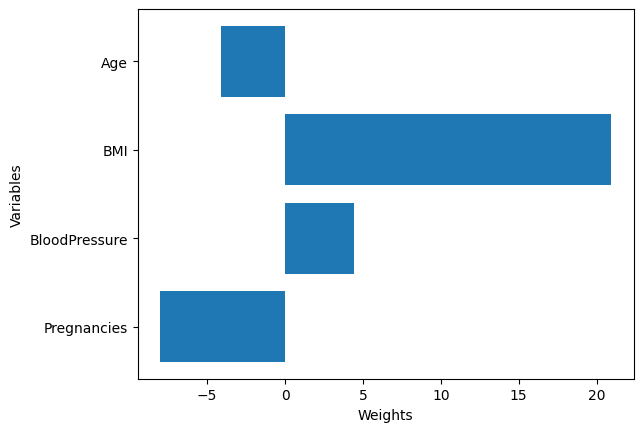

In [75]:
scaler = StandardScaler()

x_scaled_train = scaler.fit_transform(x_train)
x_scaled_test = scaler.fit_transform(x_test)

model = LinearRegression()
model.fit(x_scaled_train, y_train)

weights = pd.DataFrame(
    {
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

plt.barh(weights['Feature'], weights['Coefficient'])
plt.ylabel('Variables')
plt.xlabel('Weights')

## **BMI has the highest coefficient, this means that changes in BMI have the greatest impact on predicted insulin levels.**